# 02 · Preprocessing & Feature Extraction

Raw recordings become a labeled feature table with one row per window. Each recording goes
through these steps:

1. **Trim** 1 s from each end (removes start/stop handling).
2. **Validate**: timestamps, missing values, sampling rate ≥ 50 Hz, 5–10 s duration.
3. **Harmonize**: linearly interpolate accelerometer and gyroscope onto one shared 50 Hz grid.
4. **Window**: 2 s windows, 0.5 s step (75 % overlap).
5. **Extract** 56 features per window.

In [1]:
# --- Environment setup (works locally and in Google Colab) ---
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_URL = "https://github.com/Orrie-Dan/Human-Activity-HMM.git"
    ROOT = Path("/content/human-activity-hmm")
    if not ROOT.exists():
        !git clone -q {REPO_URL} {ROOT}
    %cd {ROOT}
    !pip install -q -r requirements.txt
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Raw recordings are not in git. In Colab, upload a zip whose top level holds the
# p01_<activity>_<nn>/ folders and metadata.csv (i.e. the contents of data/raw/).
RAW = ROOT / "data" / "raw"
if IN_COLAB and not any(RAW.glob("p*_*_*")):
    import io, zipfile
    from google.colab import files
    for name, content in files.upload().items():
        zipfile.ZipFile(io.BytesIO(content)).extractall(RAW)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src.visualization import apply_style

apply_style()
pd.set_option("display.precision", 3)


## Cleaning and resampling

One recording before and after harmonization:

In [3]:
from src.data_loader import load_recording
from src.dataset import process_recording

rec = config.RAW_DATA_DIR / "p01_walking_02"
acc, gyro = load_recording(rec)
signals = process_recording(rec)
print(f"raw: accelerometer {len(acc)} rows, gyroscope {len(gyro)} rows (~100 Hz)")
print(f"harmonized: {len(signals)} rows at {config.DEFAULT_RECORDING_CONFIG.target_sampling_rate_hz:.0f} Hz, "
      f"{signals['timestamp'].iloc[-1]:.2f} s")
signals.head()

raw: accelerometer 1090 rows, gyroscope 1090 rows (~100 Hz)
harmonized: 446 rows at 50 Hz, 8.90 s


,timestamp,acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z
0,0.00,-0.149,-0.207,0.127,-0.426,-0.426,0.131
1,0.02,-0.084,-0.296,-0.006,-0.433,-0.383,0.131
2,0.04,-0.275,-0.432,-0.359,-0.386,-0.247,0.234
3,0.06,-0.267,-0.196,0.058,-0.271,-0.010,0.267
4,0.08,-0.138,-0.285,-0.313,-0.064,-0.038,0.229


**Why 50 Hz?** Human movement is concentrated well below 20 Hz (walking and jumping are about
1–3 Hz), so 50 Hz (Nyquist 25 Hz) keeps all the useful information. It is also a rate most
phones can reach, so data from different devices can be put on the same grid.

## Windowing

**Why 2 s windows with a 0.5 s step?** At about 2 steps or jumps per second, a 2 s window
contains several movement cycles. It also gives the FFT a 0.5 Hz resolution. The 0.5 s step
gives 9–16 windows for first-session recordings, but only 2–6 for the short second-session
ones. Overlapping windows are correlated, which is why we later split data by recording,
never by window.

## Feature extraction

For each of the 8 channels (6 axes plus `acc_mag` and `gyro_mag`):

| Domain | Features |
|---|---|
| time | mean, std, min, max |
| frequency | dominant frequency (largest non-DC FFT bin), spectral energy (signal power) |

Plus, for each sensor, the **signal magnitude area** and the 3 pairwise **axis correlations**.
That gives 8 × 6 + 2 + 6 = **56 features**.

In [4]:
from src.dataset import build_feature_table

table, skipped = build_feature_table()
print("skipped:", skipped or "none")
config.FEATURES_FILE.parent.mkdir(parents=True, exist_ok=True)
table.to_csv(config.FEATURES_FILE, index=False)
print(f"{len(table)} windows x {table.shape[1] - 5} features -> {config.FEATURES_FILE.relative_to(ROOT)}")
table.groupby("activity").agg(recordings=("recording", "nunique"), windows=("recording", "size"))

skipped: none
321 windows x 56 features -> data\processed\features.csv


,recordings,windows
activity,,
jumping,9,74
standing,12,77
still,12,82
walking,12,88


## Save processed features

The table above is saved to `data/processed/features.csv`. Below is how the key features are distributed per activity (one dot per window, bar = median). Variability features use a log scale.

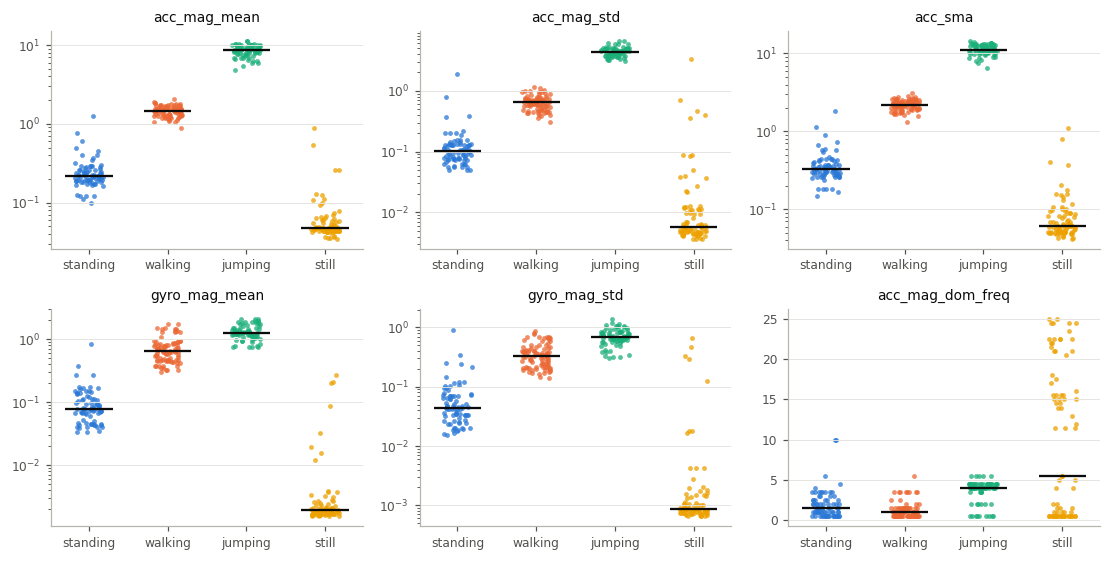

In [5]:
from src.visualization import plot_feature_by_activity

plot_feature_by_activity(
    table,
    ["acc_mag_mean", "acc_mag_std", "acc_sma", "gyro_mag_mean", "gyro_mag_std", "acc_mag_dom_freq"],
    log_scale=["acc_mag_mean", "acc_mag_std", "acc_sma", "gyro_mag_mean", "gyro_mag_std"],
);

- Movement intensity (`acc_mag_mean`, `acc_sma`, `gyro_mag_*`) orders the activities clearly:
  still < standing < walking < jumping, with a factor of about 4–7 between neighbors.
- **standing vs still**, the hardest pair, still differ about 20× in `acc_mag_std` and about
  40–50× in `gyro_mag_mean`. The few still windows near the standing range come from the
  phone being put down (`p01_still_01`, `_02`, `_05`).
- `acc_mag_dom_freq` is about 1 Hz for walking and about 4 Hz for jumping. The magnitude
  probably peaks twice per jump (take-off and landing). For still it is meaningless (the FFT
  of sensor noise, scattered up to 25 Hz), which is one reason a smaller feature set could
  help later.

Features are **not** standardized here. Standardization is fitted on the training
recordings only, inside the training step.